# Rejecting shattered fragments by inter-arrival time: three ways to set the cutoff

When an ice particle or a large drop strikes a probe's arm tips it can break into a burst of
fragments that cross the sample volume microseconds apart. Real particles arrive as a Poisson
process, so their inter-arrival times are exponentially distributed around the mean gap
(milliseconds at typical concentrations); fragments of one burst arrive far closer together.
On logarithmic bins the inter-arrival histogram is **bimodal**, and every shattering correction
by inter-arrival time is a choice of where to cut between the two modes.

This notebook compares three choices on synthetic particle times whose truth is known:

1. **A fixed threshold.** A 6 µs cutoff, one field campaign's setting of UIOOPS's
   `defaultIntArrThresh` for the 2D-S (the stock value is `1e-6`, 1 µs; the change is recorded in
   `docs/developer/CONSTANT_PROVENANCE.md`).
2. **A smoothed-minimum trough**: smooth the log-binned histogram and cut at its minimum
   between the two peaks.
3. **The Field et al. (2006) per-second double-Poisson fit**, as NCAR's Process2D implements it
   (GitHub `NCAR/aircraft_oap`, Apache-2.0; related work), transcribed in the opt-in
   enhancement `arrayprobe_enhancements.field2006_shatter`. Each second it fits a two-mode
   Poisson mixture to the last 400 inter-arrival times, cuts at `0.05 / a1` (1/20 of the slow
   mode's characteristic time) and returns a factor that restores the real particles the cut
   removes.

**The Field (2006) enhancement is opt-in, off by default, and not part of any standard processing
run**: it is called directly here, beside the data, and nothing in a standard run uses it.

All three methods below use the same pair rule, so that only the cutoff differs: a particle is
rejected when its own gap or the gap that follows it is below the cutoff (the rule the
enhancement's `apply` uses; applying it to the other two is this notebook's choice).

**Before this:** [05_triage_and_gallery](../1_getting_started/05_triage_and_gallery.ipynb) (Looking at particles: a contact sheet, a gallery, and the triage page). **Related:** [13_shattering](13_shattering.ipynb). **Needs:** the enhancements package and `pip install "arrayprobe[extra]"` (matplotlib).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/5_data_quality/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

Make the shattering tool importable and load it. It ships outside the core package, so the path to its source folder is added to the search path first.

In [2]:
import sys

import numpy as np

# The enhancement lives in this checkout's enhancements_uiops/ package; put it first on the path.
sys.path.insert(0, str(Path("enhancements_uiops/src").resolve()))
from arrayprobe_enhancements import field2006_shatter as f6

## Synthetic particle times (fixed seed)

Sixty seconds of real particles at 150 per second (Poisson), plus 25 shattering events per
second, each a burst of 2-8 fragments whose gaps are exponential with a 3 µs mean. Every
fragment is labelled, so each method's errors can be counted exactly.

In [3]:
rng = np.random.default_rng(20261005)
DUR = 60.0
REAL_RATE = 150.0      # real particles per second
EVENT_RATE = 25.0      # shattering events per second
FRAG_MEAN = 3e-6       # mean gap between fragments of one event, s

t_real = np.sort(rng.uniform(0, DUR, rng.poisson(REAL_RATE * DUR)))
frags = []
for start in rng.uniform(0, DUR, rng.poisson(EVENT_RATE * DUR)):
    k = rng.integers(2, 9)
    frags.append(start + np.cumsum(np.concatenate([[0.0], rng.exponential(FRAG_MEAN, k - 1)])))
t_frag = np.concatenate(frags)

t = np.concatenate([t_real, t_frag])
is_frag = np.concatenate([np.zeros(t_real.size, bool), np.ones(t_frag.size, bool)])
order = np.argsort(t, kind="stable")
t, is_frag = t[order], is_frag[order]
keep = t < DUR
t, is_frag = t[keep], is_frag[keep]
gap = np.diff(t, prepend=0.0)          # inter-arrival time, s (first particle: its time)
sec = np.floor(t).astype(int)          # 1-Hz second of each particle
print(f"{t.size} particles: {(~is_frag).sum()} real, {is_frag.sum()} fragments")

16517 particles: 8956 real, 7561 fragments


## The inter-arrival histogram on logarithmic bins

Ten bins per decade from 0.1 µs to 1 s. The fragment mode sits near a few microseconds, the
real-particle mode near 1/150 s; the smoothed curve (a five-bin running mean) is what the
trough method searches.

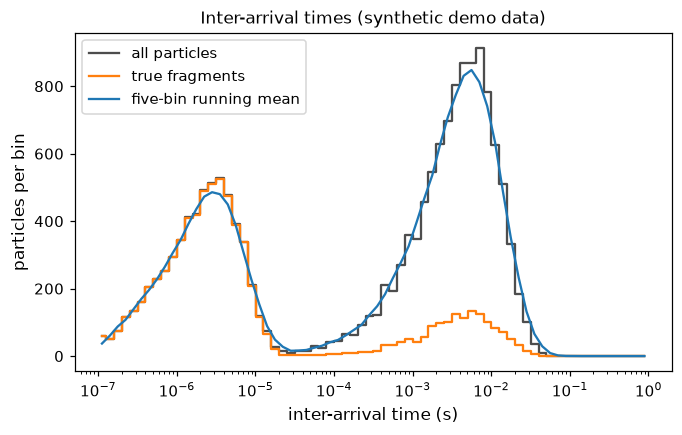

In [4]:
import matplotlib.pyplot as plt

edges = np.logspace(-7, 0, 71)
mid = np.sqrt(edges[:-1] * edges[1:])
h_all, _ = np.histogram(gap, edges)
h_frag, _ = np.histogram(gap[is_frag], edges)
smooth = np.convolve(h_all, np.ones(5) / 5, mode="same")

fig, ax = plt.subplots(figsize=(7, 4))
ax.step(mid, h_all, where="mid", color="0.3", label="all particles")
ax.step(mid, h_frag, where="mid", color="tab:orange", label="true fragments")
ax.plot(mid, smooth, color="tab:blue", label="five-bin running mean")
ax.set_xscale("log")
ax.set_xlabel("inter-arrival time (s)")
ax.set_ylabel("particles per bin")
ax.set_title("Inter-arrival times (synthetic demo data)")
ax.legend(fontsize=10)
plt.show()

*Figure 1. Inter-arrival times in the synthetic demo data: all particles, the true fragments, and a five-bin running mean of all particles, on a logarithmic time axis.*

## Three cutoffs, one pair rule

For each method: the fraction of true fragments rejected, the fraction of true real particles
lost, and the accepted concentration's difference from the true real-particle concentration, in
dB (`10 log10(estimate / truth)`; positive means fragments leak through, negative means real
particles are lost). For the Field (2006) fit the accepted counts are also shown multiplied by
its per-second correction factor (`corrected_counts`), which is how Process2D applies it.

In [5]:
def pair_reject(gap, cut):
    cut = np.broadcast_to(cut, gap.shape)
    rej = gap < cut
    rej[:-1] |= gap[1:] < cut[:-1]
    return rej


n_true = (~is_frag).sum()
rows = []


def score(name, cutoff_text, rej, n_estimate=None):
    n_est = (~rej).sum() if n_estimate is None else n_estimate
    rows.append((name, cutoff_text, 100 * rej[is_frag].mean(), 100 * rej[~is_frag].mean(),
                 10 * np.log10(n_est / n_true)))


# 1. fixed threshold
score("fixed 6 µs", "6 µs", pair_reject(gap, 6e-6))

# 2. smoothed-minimum trough between the two peaks (split at 100 µs to find them)
p_fast = np.argmax(np.where(mid < 1e-4, smooth, -1))
p_slow = np.argmax(np.where(mid > 1e-4, smooth, -1))
trough = p_fast + np.argmin(smooth[p_fast:p_slow + 1])
cut_trough = edges[trough + 1]
score("smoothed trough", f"{cut_trough * 1e6:.1f} µs", pair_reject(gap, cut_trough))

# 3. Field et al. (2006) per-second fit (opt-in enhancement)
res = f6.apply(gap, sec)
counts = np.array([(~res.rejected & (sec == s)).sum() for s in res.seconds])
n_corr = f6.corrected_counts(counts, res.corrfac).sum()
cut_text = f"{np.median(res.cutoff_s) * 1e6:.0f} µs (median)"
score("Field 2006 fit", cut_text, res.rejected)
score("Field 2006 fit x corrfac", cut_text, res.rejected, n_estimate=n_corr)

print(f"{'method':26s} {'cutoff':>18s} {'fragments rejected':>19s} {'real lost':>10s} {'conc. vs truth':>15s}")
for name, cut, fr, rl, db in rows:
    print(f"{name:26s} {cut:>18s} {fr:18.2f} % {rl:8.2f} % {db:+12.2f} dB")
print(f"median per-second fit: a1 = {np.median(res.a1):.0f} /s, a2 = {np.median(res.a2):.3g} /s, "
      f"corrfac = {np.median(res.corrfac):.3f}")

method                                 cutoff  fragments rejected  real lost  conc. vs truth
fixed 6 µs                               6 µs              93.35 %     0.32 %        +0.22 dB
smoothed trough                       31.6 µs             100.00 %     1.15 %        -0.05 dB
Field 2006 fit                280 µs (median)              95.85 %     9.07 %        -0.25 dB
Field 2006 fit x corrfac      280 µs (median)              95.85 %     9.07 %        +0.20 dB
median per-second fit: a1 = 179 /s, a2 = 3.75e+05 /s, corrfac = 1.108


## Reading the result

- **The fixed 6 µs threshold** leaves the fragments whose gaps exceed 6 µs: with a 3 µs mean
  gap a measurable share of each burst survives, and the concentration reads high. It loses
  almost no real particles, because real gaps below 6 µs are rare at this concentration. The
  right fixed value depends on the probe, the airspeed and the fragment spread, none of which
  a constant knows.
- **The smoothed trough** adapts to the data: it lands between the modes and here rejects
  nearly every fragment at a small real-particle loss. It needs enough particles for the two
  peaks to be resolved, and it fails when the modes overlap or one is missing.
- **The Field (2006) fit** cuts at 1/20 of the slow mode's characteristic time, far above the
  fragment mode, so it rejects fragments and a known share of real particles, and then
  multiplies the counts back up by its correction factor. Its loss of real particles is by
  design; the factor is what makes the concentration right on average.

Which method suits a dataset is a judgement for the user; on real data no truth is available,
so check that the cutoff sits in the histogram's trough before trusting any of them. The
Field (2006) module is an opt-in enhancement, not part of any engine, and no processing run
applies it.